# Food Delivery Time Prediction
Alur lengkap: EDA → split → cleaning → feature engineering → modeling → evaluasi (tanpa Pipeline).
Jalankan cell secara berurutan dari atas.

## 1. Import & load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Memperbaiki file_id agar hanya berisi ID filenya saja, bukan seluruh URL
file_id = '1oi1rd1LF3rZ--MxsOXVJ9Vhae39gDlsn'
url = f'https://drive.google.com/uc?export=download&id={file_id}'
df = pd.read_csv(url, sep=';')
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


## 2. EDA

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB
          Order_ID  Distance_km  Preparation_Time_min  Courier_Experience_yrs  \
count  1000.000000  1000.000000           1000.000000              970.000000   
mean    500.500000    10.059970             16.982000                4.579381   
std   

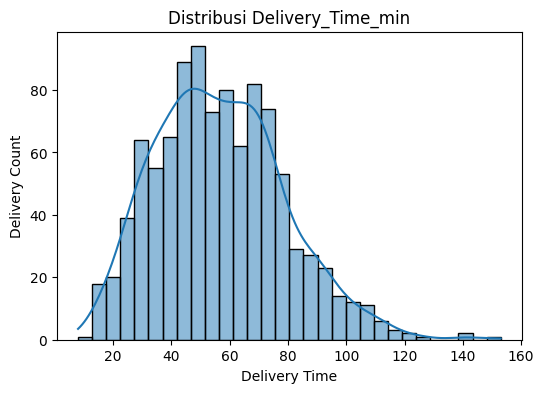

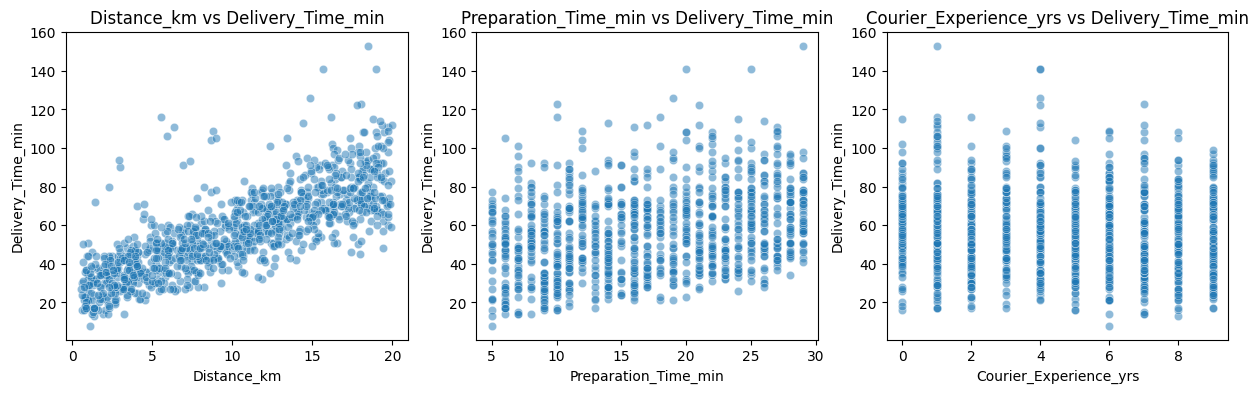

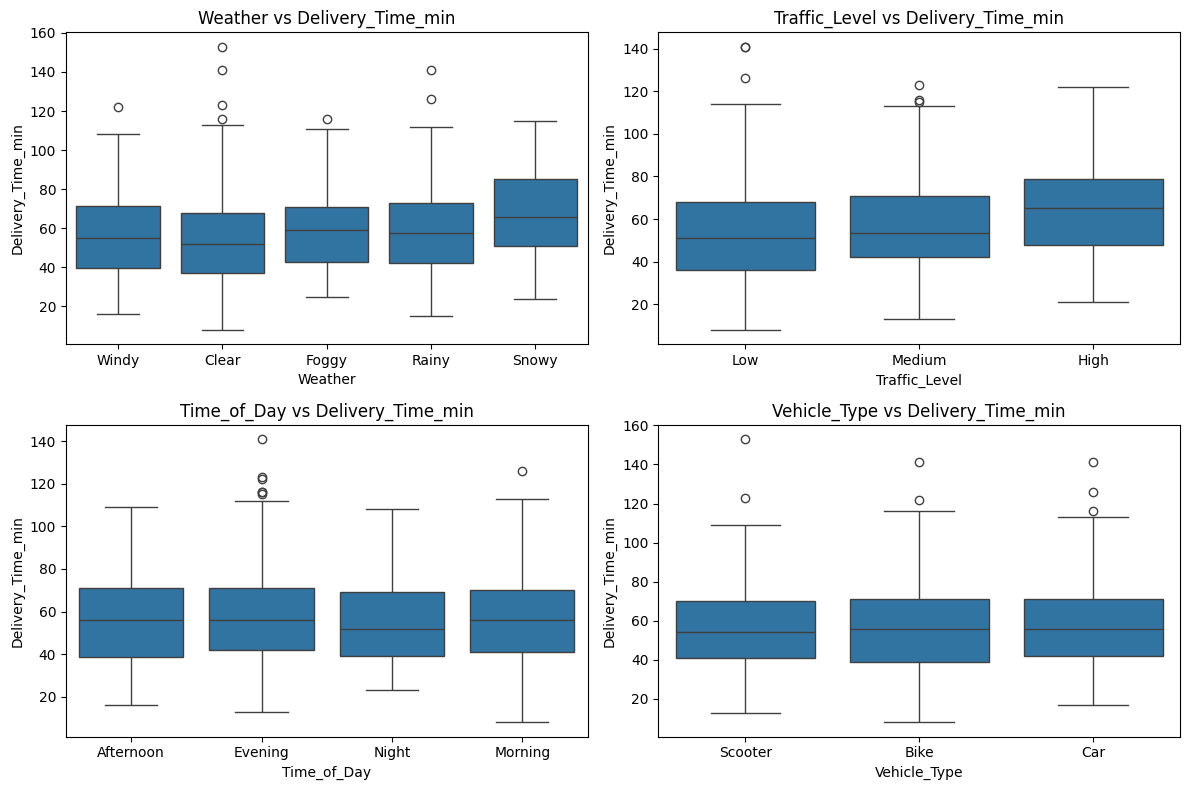

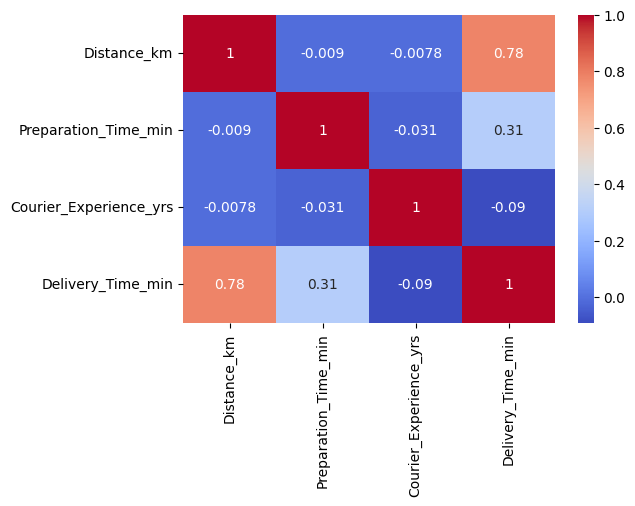

In [3]:
df.info()
print(df.describe())
print("\nMissing value per kolom:\n", df.isnull().sum())

# Distribusi target
plt.figure(figsize=(6, 4))
sns.histplot(df['Delivery_Time_min'], bins=30, kde=True)
plt.title('Distribusi Delivery_Time_min')
plt.ylabel('Delivery Count')
plt.xlabel('Delivery Time')

plt.show()

# Hubungan fitur numerik dengan target
num_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.scatterplot(data=df, x=col, y='Delivery_Time_min', ax=ax, alpha=0.5)
    ax.set_title(f'{col} vs Delivery_Time_min')
plt.show()

# Hubungan fitur kategorikal dengan target
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.boxplot(data=df, x=col, y='Delivery_Time_min', ax=ax)
    ax.set_title(f'{col} vs Delivery_Time_min')
plt.tight_layout()
plt.show()

# Korelasi numerik
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols + ['Delivery_Time_min']].corr(), annot=True, cmap='coolwarm')
plt.show()

## 3. Split data (SEBELUM cleaning agar tidak ada data leakage)

In [4]:
X = df.drop(columns=['Delivery_Time_min', 'Order_ID'])
y = df['Delivery_Time_min']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# .copy() supaya tidak muncul SettingWithCopyWarning
X_train, X_test = X_train.copy(), X_test.copy()
print(X_train.shape, X_test.shape)

(800, 7) (200, 7)


Pada tahap pemisahan data (data splitting), dataset terlebih dahulu dibagi menjadi variabel input ($X$) dan variabel target ($y$). Kolom Delivery_Time_min dipisahkan dari variabel $X$ karena berperan sebagai target yang ingin diprediksi, sekaligus untuk mencegah terjadinya kebocoran data (data leakage). Selain itu, kolom Order_ID juga dihapus dari variabel $X$ karena merupakan identitas unik yang tidak memiliki nilai informatif untuk prediksi.   Selanjutnya, data dibagi menjadi dua bagian dengan rasio 80:20 menggunakan train_test_split, yaitu 80% sebagai data latih (train) sebanyak 800 sampel dan 20% sebagai data uji (test) sebanyak 200 sampel. Penggunaan parameter random_state=42 memastikan hasil pembagian data bersifat konsisten, sementara perintah .copy() digunakan untuk menghindari peringatan sistem saat manipulasi data berikutnya.

## 4. Cleaning: missing value (nilai pengisi dihitung dari TRAIN saja)

In [5]:
cat_missing = ['Weather', 'Traffic_Level', 'Time_of_Day']
for col in cat_missing:
    modus = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(modus)
    X_test[col] = X_test[col].fillna(modus)

median_exp = X_train['Courier_Experience_yrs'].median()
X_train['Courier_Experience_yrs'] = X_train['Courier_Experience_yrs'].fillna(median_exp)
X_test['Courier_Experience_yrs'] = X_test['Courier_Experience_yrs'].fillna(median_exp)

print("Sisa missing (train):", X_train.isnull().sum().sum())
print("Sisa missing (test) :", X_test.isnull().sum().sum())

Sisa missing (train): 0
Sisa missing (test) : 0


Pada tahap penanganan data yang hilang (missing value), pengisian nilai kosong dilakukan dengan memanfaatkan statistik yang dihitung hanya dari data latih (train) untuk mencegah terjadinya kebocoran data (data leakage). Modus untuk Kolom Kategorikal (Weather, Traffic_Level, Time_of_Day):
Alasan: Kolom-kolom ini berisi data berupa teks/kategori (bukan angka/ukuran). Median untuk Kolom Numerik (Courier_Experience_yrs): Alasan: Kolom ini berisi data angka (tahun pengalaman).

## 5. Cleaning: outlier (capping IQR, batas dari TRAIN, hanya fitur numerik)

In [6]:
for col in ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((X_train[col] < low) | (X_train[col] > high)).sum()
    print(f"{col}: {n_out} outlier di train (batas {low:.2f} - {high:.2f})")
    X_train[col] = X_train[col].clip(low, high)
    X_test[col] = X_test[col].clip(low, high)

Distance_km: 0 outlier di train (batas -9.59 - 29.66)
Preparation_Time_min: 0 outlier di train (batas -7.00 - 41.00)
Courier_Experience_yrs: 0 outlier di train (batas -5.50 - 14.50)


Pada tahap cleaning outlier, dilakukan pemeriksaan nilai pencilan pada tiga fitur numerik (Distance_km, Preparation_Time_min, dan Courier_Experience_yrs) menggunakan metode Interquartile Range (IQR) pada data train. Hasil evaluasi menunjukkan bahwa tidak terdapat nilai outlier pada ketiga fitur tersebut, karena seluruh nilai data masih berada di dalam batas toleransi wajar ($Q1 - 1.5 \times IQR$ hingga $Q3 + 1.5 \times IQR$). Dengan demikian, data dinyatakan bersih dan tidak memerlukan pemangkasan (capping), sehingga dapat langsung dilanjutkan ke tahap feature engineering

## 6. Feature engineering (HANYA dari kolom input, tidak memakai target)

In [7]:
traffic_map = {'Low': 0, 'Medium': 1, 'High': 2}

for d in (X_train, X_test):
    d['Traffic_Ord'] = d['Traffic_Level'].map(traffic_map)
    d['Dist_x_Traffic'] = d['Distance_km'] * d['Traffic_Ord']
    d['Dist_per_Exp'] = d['Distance_km'] / (d['Courier_Experience_yrs'] + 1)
    d['Bad_Weather'] = d['Weather'].isin(['Rainy', 'Snowy', 'Foggy']).astype(int)

X_train = X_train.drop(columns=['Traffic_Level'])
X_test = X_test.drop(columns=['Traffic_Level'])

Langkah ini diawali dengan mengonversi tingkat kemacetan (Traffic_Level) menjadi skala angka bertingkat (Traffic_Ord). Selanjutnya dibuat tiga fitur turunan, yaitu Dist_x_Traffic untuk mengukur beban pengiriman berdasarkan kombinasi jarak dan kemacetan, Dist_per_Exp untuk melihat rasio jarak terhadap pengalaman kurir (dengan penambahan +1 agar tidak terjadi pembagian dengan nol), serta Bad_Weather sebagai penanda biner untuk kondisi cuaca buruk. Proses diakhiri dengan menghapus kolom teks asli Traffic_Level karena nilainya sudah diwakili oleh fitur numerik baru.

## 7. Encoding kategorikal (one-hot), lalu samakan kolom test dengan train

In [8]:
X_train = pd.get_dummies(X_train, columns=['Weather', 'Time_of_Day', 'Vehicle_Type'],
                         drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=['Weather', 'Time_of_Day', 'Vehicle_Type'],
                        drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape, X_test.shape)
X_train.head()

(800, 16) (200, 16)


,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Traffic_Ord,Dist_x_Traffic,Dist_per_Exp,Bad_Weather,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Car,Vehicle_Type_Scooter
29,18.05,10,7.0,1,18.05,2.256250,0,0,0,0,0,1,0,0,0,1
535,2.14,18,3.0,2,4.28,0.535000,0,0,0,0,0,1,0,0,0,0
695,3.23,17,9.0,2,6.46,0.323000,0,0,0,0,0,0,0,0,0,0
557,7.51,27,6.0,0,0.00,1.072857,1,0,1,0,0,1,0,0,1,0
836,4.62,8,3.0,1,4.62,1.155000,1,0,1,0,0,0,0,0,1,0


Pada tahap ini, fitur bertipe kategorikal/teks (Weather, Time_of_Day, dan Vehicle_Type) diubah menjadi bentuk angka biner (0 atau 1) menggunakan teknik One-Hot Encoding (pd.get_dummies). Setelah itu, struktur kolom pada data test disesuaikan agar sama persis dengan data train untuk memastikan konsistensi fitur sebelum masuk ke tahap pemodelan.

## 8. Modeling

In [9]:
models = {
    'Baseline (rata-rata)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=200, learning_rate=0.05,
                            max_depth=3, random_state=42),
}

preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)

Pada tahap pemodelan, dilakukan pelatihan 4 algoritma regresi yang berbeda pada data train, yaitu Dummy Regressor (sebagai acuan dasar/baseline), Linear Regression, XGBoost, dan Random Forest. Proses ini bertujuan untuk membandingkan performa berbagai jenis algoritma dalam memprediksi durasi pengiriman

## 9. Evaluasi (MAE, RMSE, R2 pada data test)

In [10]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred),
    })

results = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
results.round(3)

,Model,MAE,RMSE,R2
0,Linear Regression,6.052,8.940,0.822
1,XGBoost,6.657,9.559,0.796
2,Random Forest,6.795,9.605,0.794
3,Baseline (rata-rata),17.501,21.232,-0.006


Pada tahap evaluasi, performa setiap model diukur menggunakan metrik MAE, RMSE, dan $R^2$ pada data test yang diurutkan berdasarkan nilai RMSE terkecil. Hasil evaluasi menunjukkan bahwa Linear Regression menjadi model terbaik dengan tingkat eror terendah (MAE = 6.052 menit, RMSE = 8.940) serta mampu menjelaskan 82.2% variasi data ($R^2 = 0.822$). Algoritma berbasis tree seperti XGBoost ($R^2 = 0.796$) dan Random Forest ($R^2 = 0.794$) menyusul di urutan berikutnya, sementara model Baseline berkinerja paling buruk. Dengan demikian, Linear Regression dipilih sebagai model utama untuk melakukan prediksi waktu pengiriman

## 10. Interpretasi: feature importance (Random Forest)

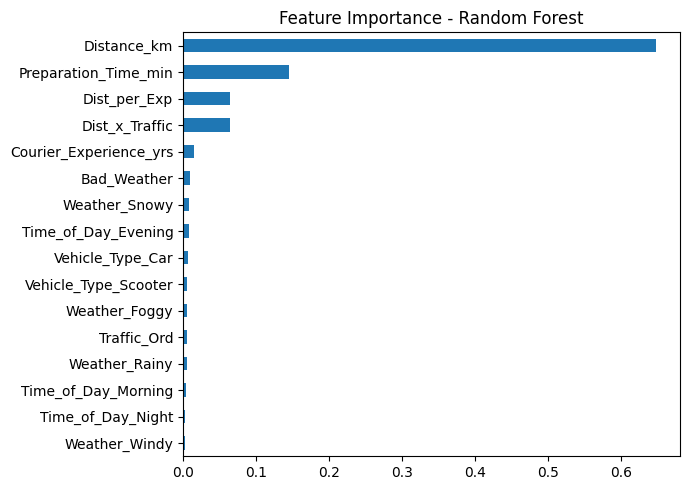

In [11]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(7, 5))
imp.plot(kind='barh')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.show()

Berdasarkan analisis feature importance dari model Random Forest, jarak pengiriman (Distance_km) menjadi fitur yang paling berpengaruh secara dominan terhadap durasi pengiriman, diikuti oleh waktu persiapan (Preparation_Time_min). Fitur-fitur lain seperti rasio jarak, tingkat kemacetan, dan jenis cuaca memiliki kontribusi pengaruh yang relatif lebih kecil.

## 11. Aktual vs prediksi (model terbaik)

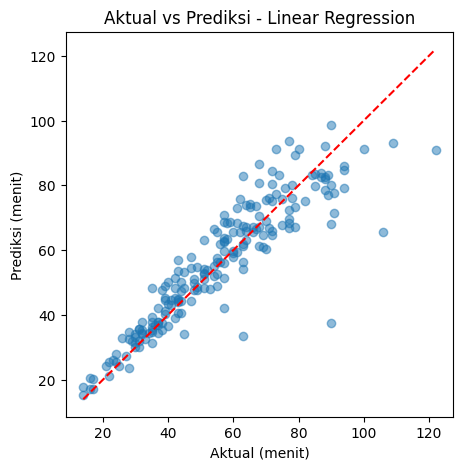

In [12]:
best_name = results.loc[0, 'Model']
y_best = preds[best_name]

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_best, alpha=0.5)
lims = [min(y_test.min(), y_best.min()), max(y_test.max(), y_best.max())]
plt.plot(lims, lims, 'r--')
plt.xlabel('Aktual (menit)')
plt.ylabel('Prediksi (menit)')
plt.title(f'Aktual vs Prediksi - {best_name}')
plt.show()

Visualisasi grafik sebaran (scatter plot) antara nilai aktual dan hasil prediksi dari model terbaik menunjukkan titik-titik data yang menyebar mengikuti garis lurus ideal (garis merah putus-putus). Hal ini mengonfirmasi bahwa model mampu memprediksi waktu pengiriman secara cukup akurat dan konsisten sesuai pola data sebenarnya.    

## 12. Fungsi preprocessing untuk data baru

In [15]:
def preprocess_new(df_new):
    d = df_new.copy()

    d['Courier_Experience_yrs'] = d['Courier_Experience_yrs'].fillna(median_exp)

    d['Traffic_Ord'] = d['Traffic_Level'].map(traffic_map)
    d['Dist_x_Traffic'] = d['Distance_km'] * d['Traffic_Ord']
    d['Dist_per_Exp'] = d['Distance_km'] / (d['Courier_Experience_yrs'] + 1)
    d['Bad_Weather'] = d['Weather'].isin(['Rainy', 'Snowy', 'Foggy']).astype(int)
    d = d.drop(columns=['Traffic_Level'])

    d = pd.get_dummies(d, columns=['Weather', 'Time_of_Day', 'Vehicle_Type'], dtype=int)
    d = d.reindex(columns=X_train.columns, fill_value=0)
    return d

## 13. Prediksi waktu pengantaran dengan data baru (Linear Regression)

In [16]:
new_data = pd.DataFrame({
    'Distance_km':            [5.0, 12.5, 20.0],
    'Weather':                ['Clear', 'Rainy', 'Foggy'],
    'Traffic_Level':          ['Low', 'High', 'Medium'],
    'Time_of_Day':            ['Morning', 'Evening', 'Night'],
    'Vehicle_Type':           ['Bike', 'Scooter', 'Car'],
    'Preparation_Time_min':   [10, 20, 25],
    'Courier_Experience_yrs': [3.0, 1.0, 5.0],
})

X_new = preprocess_new(new_data)

best_model = models['Linear Regression']
hasil = new_data.copy()
hasil['Prediksi_Waktu_min'] = best_model.predict(X_new).round(1)
hasil

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Prediksi_Waktu_min
0,5.0,Clear,Low,Morning,Bike,10,3.0,28.9
1,12.5,Rainy,High,Evening,Scooter,20,1.0,78.2
2,20.0,Foggy,Medium,Night,Car,25,5.0,98.0
